## Playback quality test: Standard vs High

Picks ONE game and captures its first few clips twice from the Synergy player -- once on **Standard**, once on **High** --
into a separate test folder (`inputs/_quality_test`). Nothing in the main parser's frames, checks or training sets is touched.

Run the cells top to bottom (same folder as `parser_nb.ipynb`, so `parser_lib`, `inputs` and your `.env` are found).
At the end: a summary table, side-by-side pictures, and a cell that deletes the test folder when you're done.

**What to send back:** the summary table and one or two of the `compare_clipNN.jpg` pictures.

In [3]:
# --- Setup: the parser's code lives in parser_lib\ (one .py file per section) --------------------------------------
# Each section cell below holds only its SETTINGS and then runs its code with run_section("<file>"). The code runs
# inside this notebook exactly as if it were still in the cell -- every function and table it makes is available to
# the cells after it. To change how something works, open parser_lib\<file>.py; to change a setting, edit the cell.
import os
PARSER_LIB = os.path.join(os.getcwd(), "parser_lib")


def run_section(name):
    """Run parser_lib/<name>.py inside this notebook (same variables as if the code were in the cell)."""
    path = os.path.join(PARSER_LIB, name if name.endswith(".py") else name + ".py")
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found -- keep the parser_lib folder next to this notebook")
    with open(path, encoding="utf-8") as fh:
        src = fh.read()
    exec(compile(src, path, "exec"), globals())


In [4]:
# UW-Whitewater Schedule and Scout Report Parser -- Portable Version
# Code: parser_lib\01_uw_whitewater_scouting_parser.py  --  settings below, then the section runs.
# --- Configuration -- edit these to match your local setup ---
INPUT_DIR = "./inputs"    # directory containing MHTML/PDF input files
OUTPUT_DIR = "../data"    # directory to write CSV output files
USE_LLM = False            # set True to enable LLM-based player comparisons (requires OPENAI_API_KEY)
APP_BASE_URL = "" or os.environ.get("UWW_APP_URL", "")
SHOW_ROWS = 15            # most tables print as a neat table capped at this many rows (the full table is still in memory / the CSVs)
REVIEW_SAVES_BRANCH = "saves"   # the app saves coach checks to this GitHub branch (so Streamlit Cloud does not restart on every save); the parser fetches it each run. "" = off

run_section("01_uw_whitewater_scouting_parser")


Input directory: ./inputs
Output directory: ../data
LLM comparisons: disabled
Reference date: 2026-1-7
Before scout: yes -- ignoring the upcoming opponent's own scouting report for this run


### Log in and load UWW's schedule (for the game's clip page)
Same as the main notebook. Run it even if you paste the game's address into `QT_GAME_URL` below -- it also opens the login session the capture uses.

In [6]:
# Every team's own FastScout schedule snapshot (MHTML) lives in INPUT_DIR alongside per-game pbp/video/box
# Code: parser_lib\02_parse_every_team_schedule_scrape_live_from.py  --  settings below, then the section runs.
FASTSCOUT_ORIGIN = "https://fastscout.fastmodelsports.com"
FASTSCOUT_DOCS_LEAGUE = "NCAAB-III"
FASTSCOUT_DOCS_SEASON = "25"

run_section("02_parse_every_team_schedule_scrape_live_from")


Found 22 schedule MHTML file(s) in ./inputs:
 - Alma Scots - Schedule.html
 - Aurora Spartans - Schedule.html
 - Carroll (WI) Pioneers - Schedule.html
 - Coe Kohawks - Schedule.html
 - Elmhurst Bluejays - Schedule.html
 - Eureka Red Devils - Schedule.html
 - Hope Flying Dutchmen - Schedule.html
 - Lawrence Vikings - Schedule.html
 - Loras Duhawks - Schedule.html
 - Ripon Red Hawks - Schedule.html
 - Simpson Storm - Schedule.html
 - St. Thomas (TX) Celts - Schedule.html
 - UW-Eau Claire Blugolds - Schedule.html
 - UW-La Crosse Eagles - Schedule.html
 - UW-Oshkosh Titans - Schedule.html
 - UW-Platteville Pioneers - Schedule.html
 - UW-River Falls Falcons - Schedule.html
 - UW-Stevens Point Pointers - Schedule.html
 - UW-Stout Blue Devils - Schedule.html
 - UW-Whitewater - Schedule.mhtml
 - UW-Whitewater - Schedule_2023.html
 - UW-Whitewater - Schedule_2024.html
  [before_scout=yes] Ignoring 12 scouting report(s) dated on/after 2026-1-7: ['1_10_26 UW-Whitewater @ UW-River Falls Falcons_sc

In [7]:
# Synergy login helper (used when the clip page asks for a Synergy login)
run_section("27_shared_video_tagging_helper_functions")


### Frame-capture functions
Loads the main notebook's frame-capture code WITHOUT capturing anything (`RUN_FRAME_CAPTURE = False`).

In [9]:
# Same settings as the main notebook's Frame capture cell -- only RUN_FRAME_CAPTURE is off
RUN_FRAME_CAPTURE = False
VISION_TEST_CLIPS = None
VISION_ONLY_GAME = None
VISION_RETAG = False
VISION_FRAMES_PER_CLIP = 5
VISION_FRAME_MAX_WIDTH = 1024
VISION_BROWSER_CHANNEL = "msedge"   # "msedge" (always on Windows) or "chrome"
VISION_HEADLESS = False             # keep False: you can watch it, and pick the quality by hand if it can't be clicked
VISION_PLAYLIST_URLS = []
VISION_MAX_GAMES_PER_RUN = 1
VISION_SKIP_DESCRIPTION = r">\s*Free Throw\s*$"
VISION_TRACK_FPS = 4
VISION_TRACK_WIDTH = 1024
VISION_TRACK_JPEG_QUALITY = 0.95
VISION_PLAYBACK_QUALITY = None      # set per pass by the test below
VISION_QUALITY_MANUAL_WAIT = 20     # if the setting can't be clicked automatically: seconds to pick it by hand
VISION_TRACK_MAX_FRAMES = 240
VISION_CACHE = os.path.join(INPUT_DIR, "uww_clip_frames.csv")    # only READ here, never written
VISION_FRAMES_DIR = os.path.join(INPUT_DIR, "_vision_frames")
VISION_COLS = ["source_label", "source_url", "position", "clip_game", "clip_date", "team", "player", "result",
               "description", "duration_s", "frame_files", "frames_captured", "track_files", "error", "test_run",
               "captured_at", "video_start_s", "track_times"]
VISION_CAPTURE_VERSION = 2

run_section("46_frame_capture")


Clips with frames: 545 of 545 in uww_clip_frames.csv


### Run the test
Pick the game by name (same format as `VISION_ONLY_GAME` in the main notebook) **or** paste its Synergy clip-page address.

In [11]:
QT_GAME = "1_3_26 UW-Oshkosh Titans @ UW-Whitewater"   # the game, same name format as its _pbp/_video files
QT_GAME_URL = ""                     # or paste the game's Synergy clip-page address here (wins over QT_GAME)
QT_CLIPS = 5                         # the first N clips (free throws skipped)
QT_QUALITIES = ["Standard", "High"]  # the player's quality settings to compare, captured in this order
QT_MAX_FRAMES_PER_CLIP = 240         # tracking frames per clip at 4 a second (240 = the whole clip up to 60 s)
QT_DIR = os.path.join(INPUT_DIR, "_quality_test")   # the TEST folder -- safe to delete (last cell)

run_section("46q_quality_test")


Quality test: 2026-01-03 UW-Oshkosh Titans
  https://editor-web.synergysports.com/video?playlistUrl=https%3a%2f%2fbasketball.synergysportstech.com%2fapi%2fgames%2f68deda8125423a1fd110a58b%2ffullgamevideo%2fclips
  first 5 clips, qualities ['Standard', 'High'], saved under ./inputs\_quality_test

=== Standard ===
    [save] Synergy login page (diagnostic) -> Synergy - Login Page (diagnostic).html
    [synergy-login] username field matched: name='Username' id='Username' type='text'
    [synergy-login] password field matched: name='Password' id='Password'
  257 clips on the page; testing the first 5
    [quality] playback quality 'Standard': selected (gear > Options > General > 'Standard' > saved/closed > page reloaded); video 0x0 before -> 1024x576 now (the size can update only when the next clip loads)
  clip 1: stream 1024x576, 89 frames
  clip 2: stream 1024x576, 117 frames
  clip 3: stream 1024x576, 41 frames
  clip 4: stream 1024x576, 65 frames
  clip 5: stream 1024x576, 189 frames


,quality,setting picked,stream size,clips,frames,KB per frame (full),KB per frame (1024),sharpness (full),sharpness (1024)
0,Standard,True,1024x576,5,501,226.4,239.1,2369.0,2369.0
1,High,True,1280x720,5,501,321.8,228.7,1745.0,1622.0



Side-by-side pictures (5): ./inputs\_quality_test\compare_clip01.jpg; ./inputs\_quality_test\compare_clip02.jpg; ./inputs\_quality_test\compare_clip03.jpg; ./inputs\_quality_test\compare_clip04.jpg; ./inputs\_quality_test\compare_clip05.jpg


### Which quality helps tracking? (player detector + jersey reader on the same clips)
Runs the parser's own detector and trained jersey reader on every version of the clips captured in BOTH qualities.
Uses the files saved above -- you don't need to capture again. A few minutes on a CPU.

In [13]:
# The jersey reader's functions, WITHOUT training anything (same paths as the main notebook)
RUN_JERSEY_RECOGNIZER = False
JERSEY_TRAIN_DIR = os.path.join(INPUT_DIR, "jersey_training")
JERSEY_MODEL_PATH = os.path.join(JERSEY_TRAIN_DIR, "jersey_recognizer.pt")
JERSEY_CROP_STYLE = "fixed"
JERSEY_MAX_HIDDEN = 0.3
run_section("48_jersey_number_recognizer")

QT_READER_DETECTOR = "yolo11s.pt"   # the parser's player detector
QT_READER_EVERY = 2                 # every 2nd frame (1 = every frame: slower, a little more exact)
run_section("46r_quality_reader_test")


Reader test on clips [1, 2, 3, 4, 5] (captured in every quality), every 2 frame(s)
  Standard (1024 wide), clip 1: 45 frames, 581 players, 555 chests, 33 sure reads
  Standard (1024 wide), clip 2: 59 frames, 898 players, 851 chests, 103 sure reads
  Standard (1024 wide), clip 3: 21 frames, 318 players, 301 chests, 47 sure reads
  Standard (1024 wide), clip 4: 33 frames, 428 players, 416 chests, 31 sure reads
  Standard (1024 wide), clip 5: 95 frames, 1411 players, 1337 chests, 197 sure reads
  High (1280 wide), clip 1: 45 frames, 862 players, 809 chests, 44 sure reads
  High (1280 wide), clip 2: 59 frames, 1283 players, 1182 chests, 132 sure reads
  High (1280 wide), clip 3: 21 frames, 440 players, 415 chests, 50 sure reads
  High (1280 wide), clip 4: 33 frames, 626 players, 594 chests, 42 sure reads
  High (1280 wide), clip 5: 95 frames, 2178 players, 2011 chests, 238 sure reads
  High (shrunk to 1024), clip 1: 45 frames, 575 players, 548 chests, 37 sure reads
  High (shrunk to 1024),

,version,frames,players found,chests read,sure >= 0.90,sure >= 0.95,players per frame,sure reads per 100 chests,avg confidence
0,Standard (1024 wide),253,3636,3460,411,273,14.37,11.9,0.514
1,High (1280 wide),253,5389,5011,506,340,21.30,10.1,0.499
2,High (shrunk to 1024),253,3584,3419,428,279,14.17,12.5,0.517


More 'sure reads per 100 chests' = more players the reader can name. The reader was trained on Standard 1024 crops, so this compares them with a reader that has only ever seen Standard -- retraining on High crops could move High's numbers.


### Same person, same frame
High at 1280 finds many more people (bench, crowd), which muddies the totals above. This matches each person in the Standard frame to the same person in the High frame and reads both chests. Run after the cell above.

In [15]:
run_section("46s_quality_paired")


Same people, Standard vs High at 1280...
Same people, Standard vs High shrunk to 1024...


,"same person, same frame (confidence >= 0.90 = sure)",High at 1280,High shrunk to 1024
0,people matched,3322,3174
1,Standard sure,395,396
2,High sure,418,397
3,"both sure, same number",338,344
4,"both sure, DIFFERENT number",0,0
5,only Standard sure,57,52
6,only High sure,80,53


Read it as: of the people both versions show, how many get a sure jersey read on Standard vs on High; 'only High sure' vs 'only Standard sure' is the real gain or loss, and 'DIFFERENT number' means one of the two sure reads is wrong.


### Look at the pictures
Each picture: Standard on top, High below; under each frame is a 2x zoom of the middle of the court.

compare_clip01.jpg


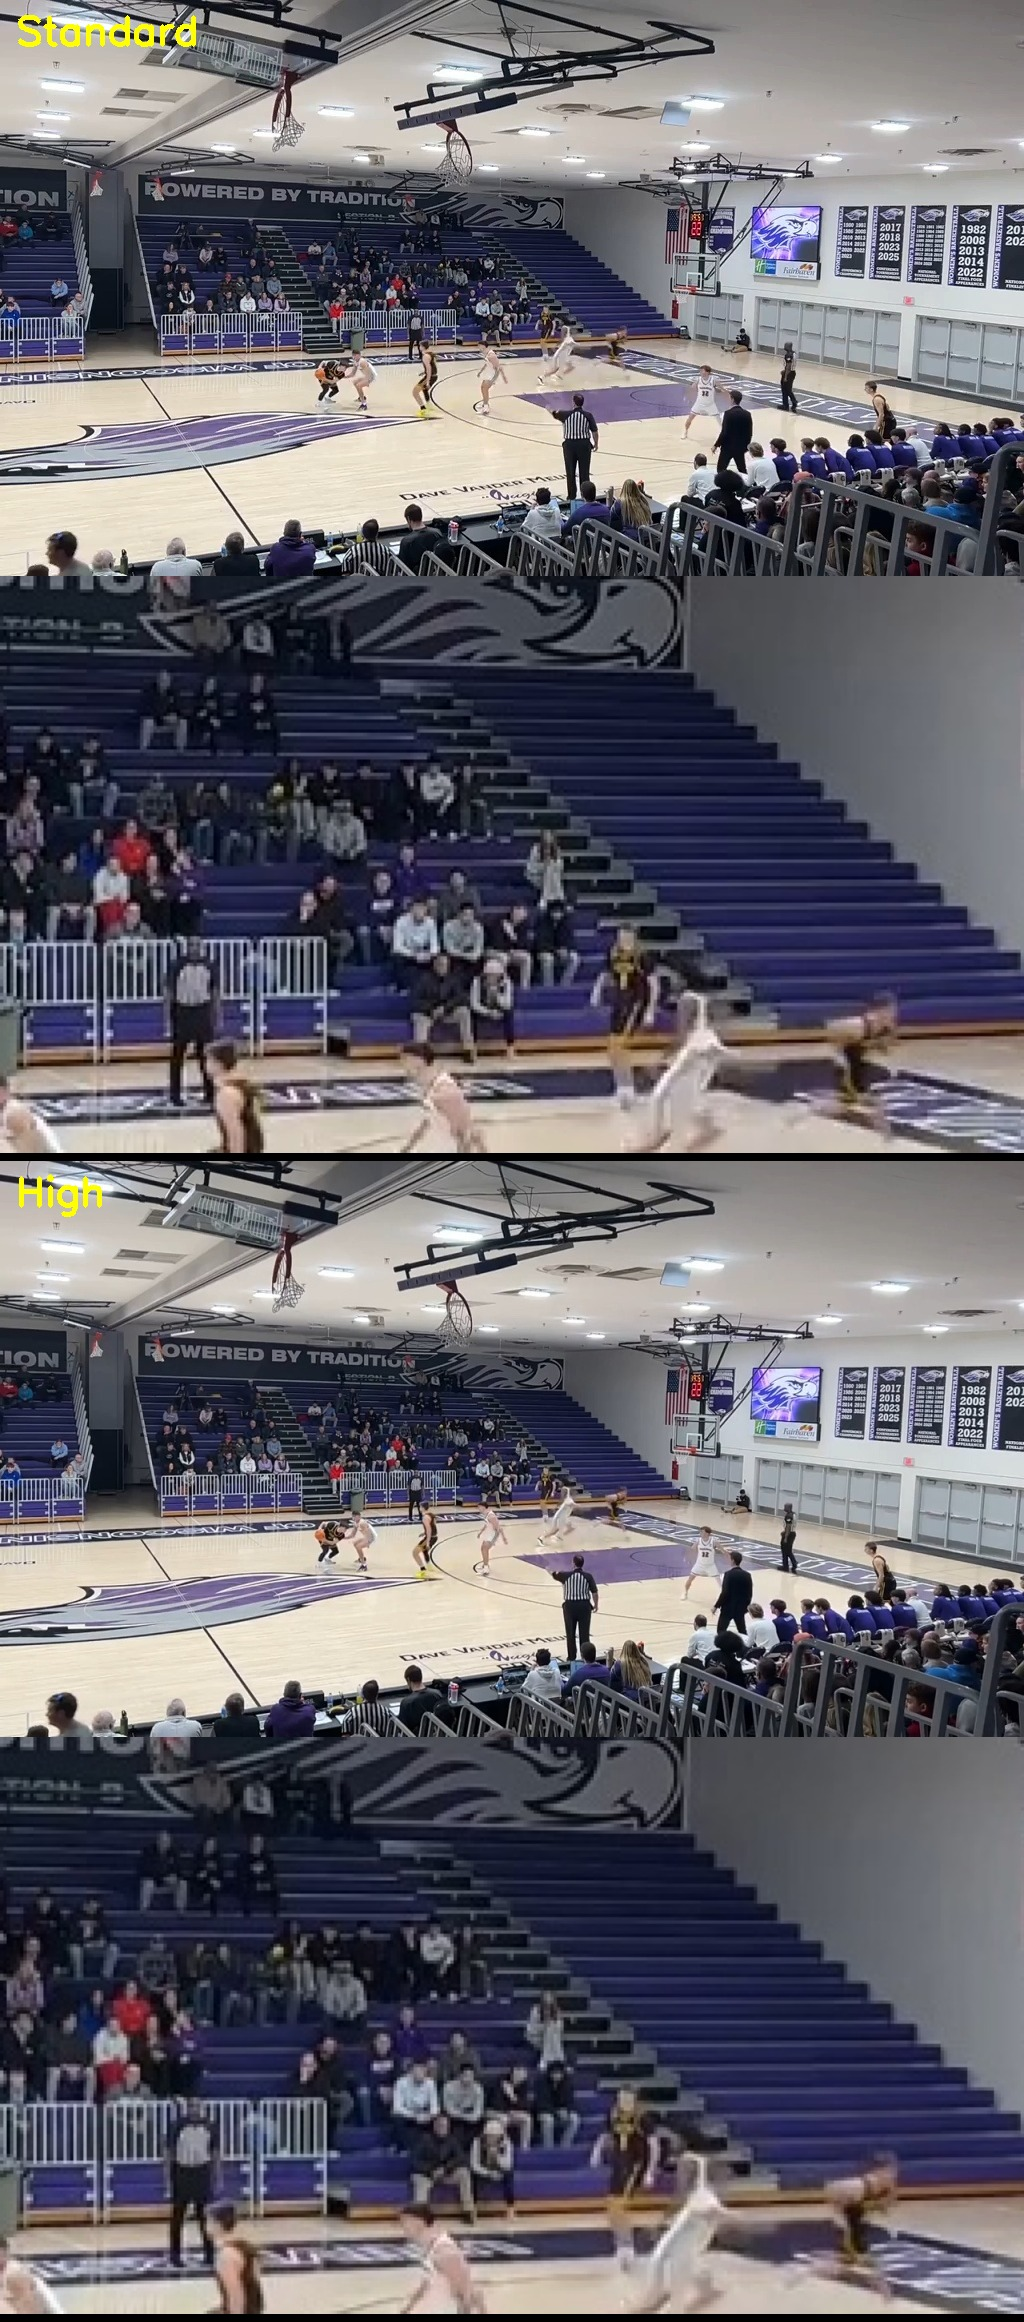

compare_clip02.jpg


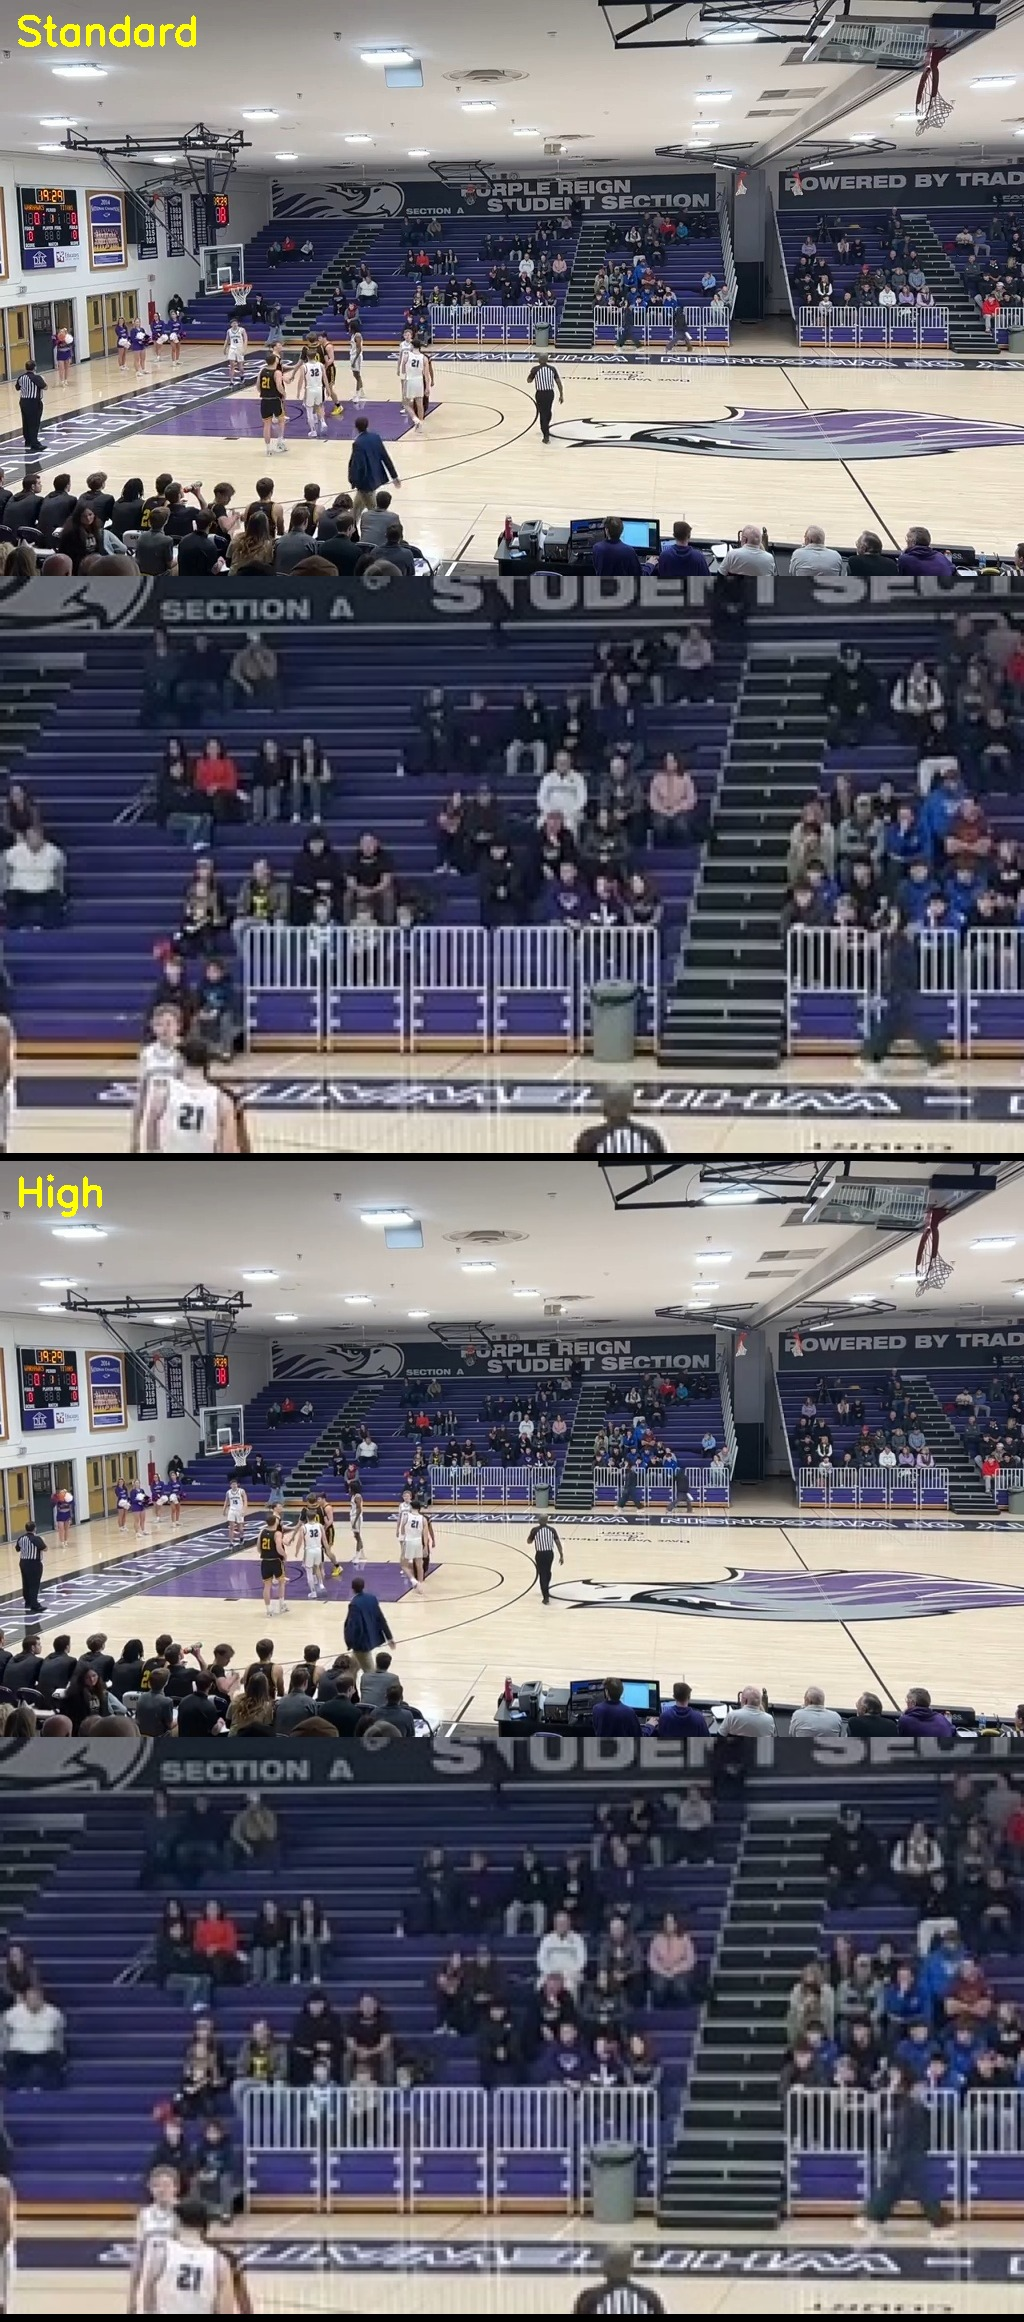

compare_clip03.jpg


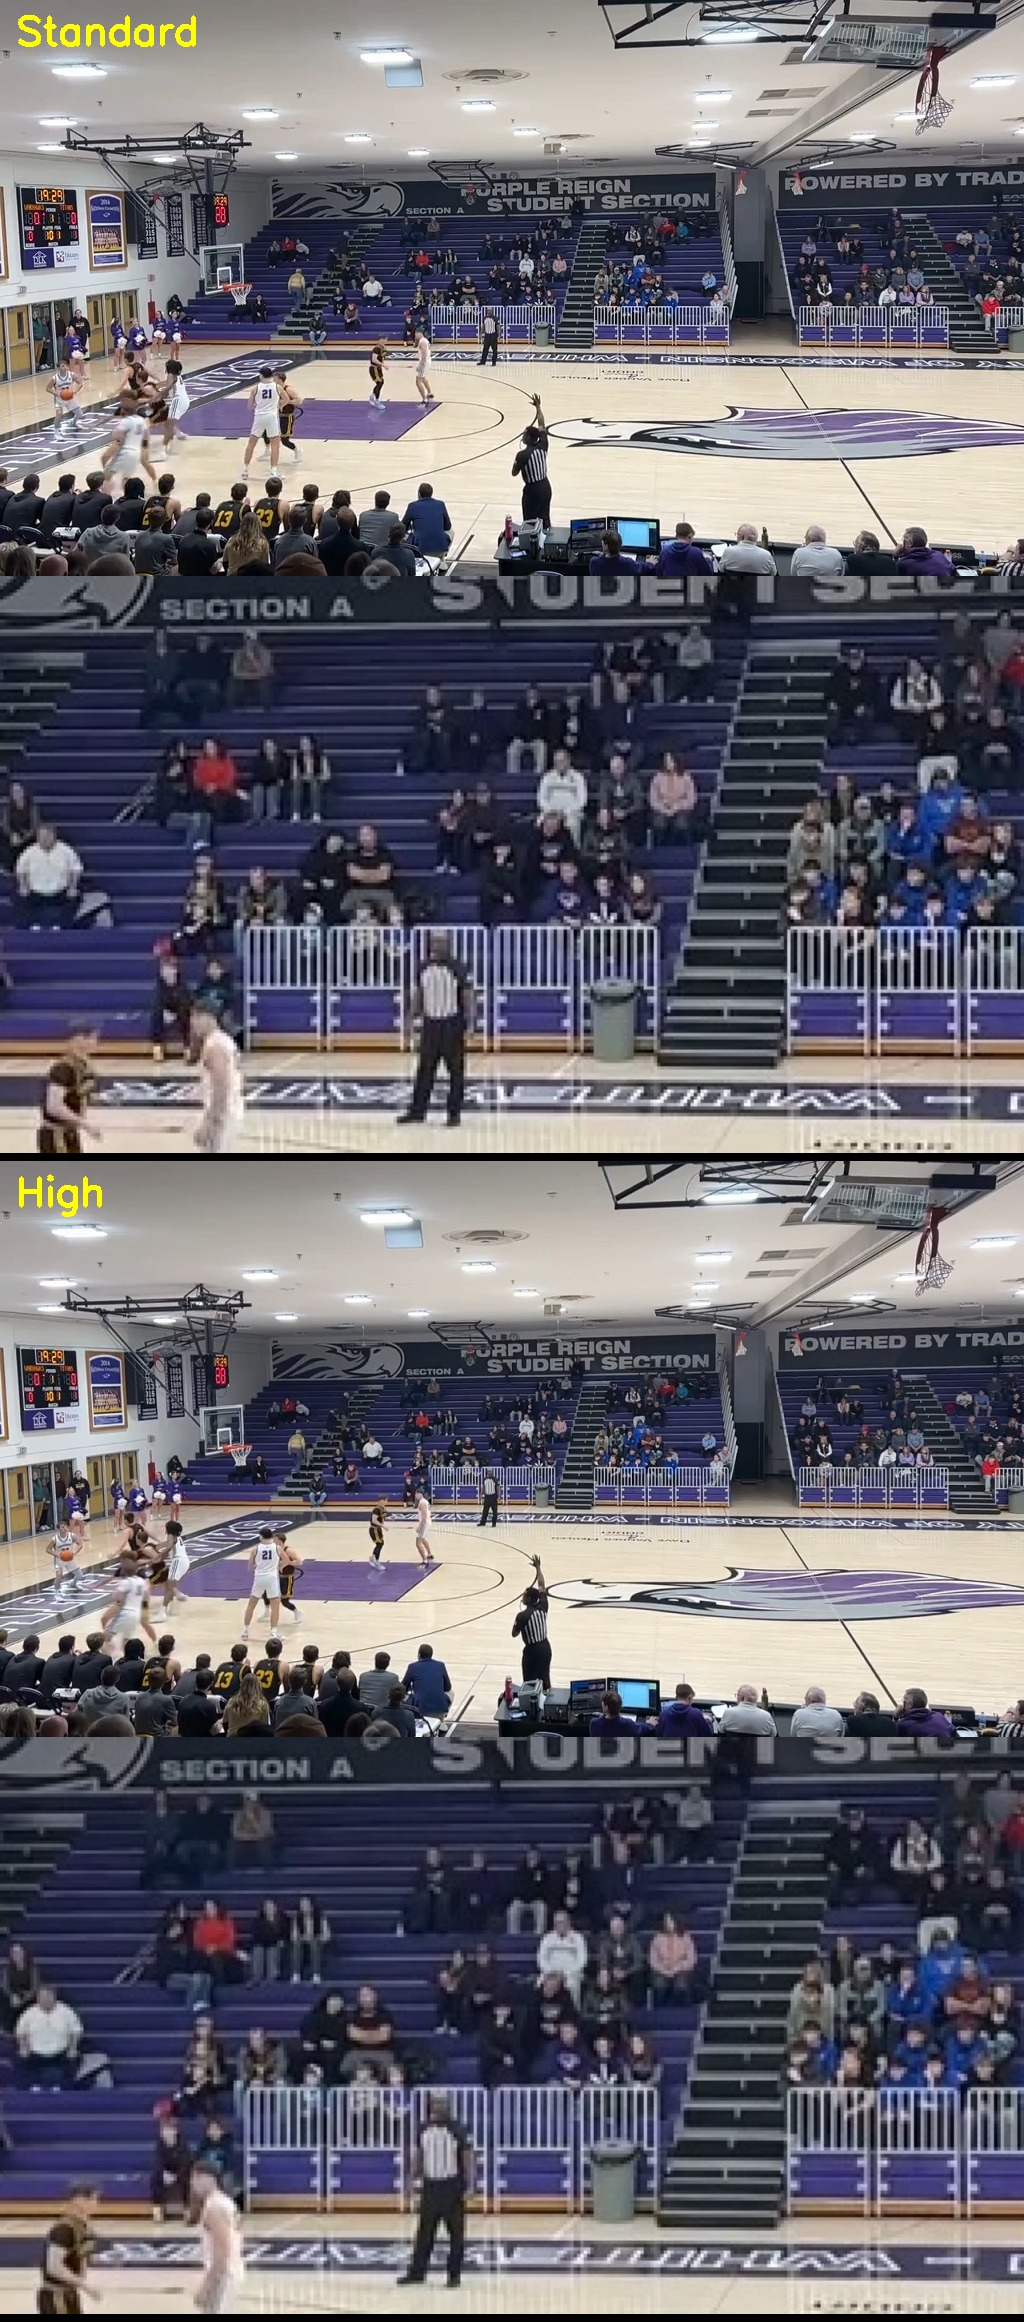

compare_clip04.jpg


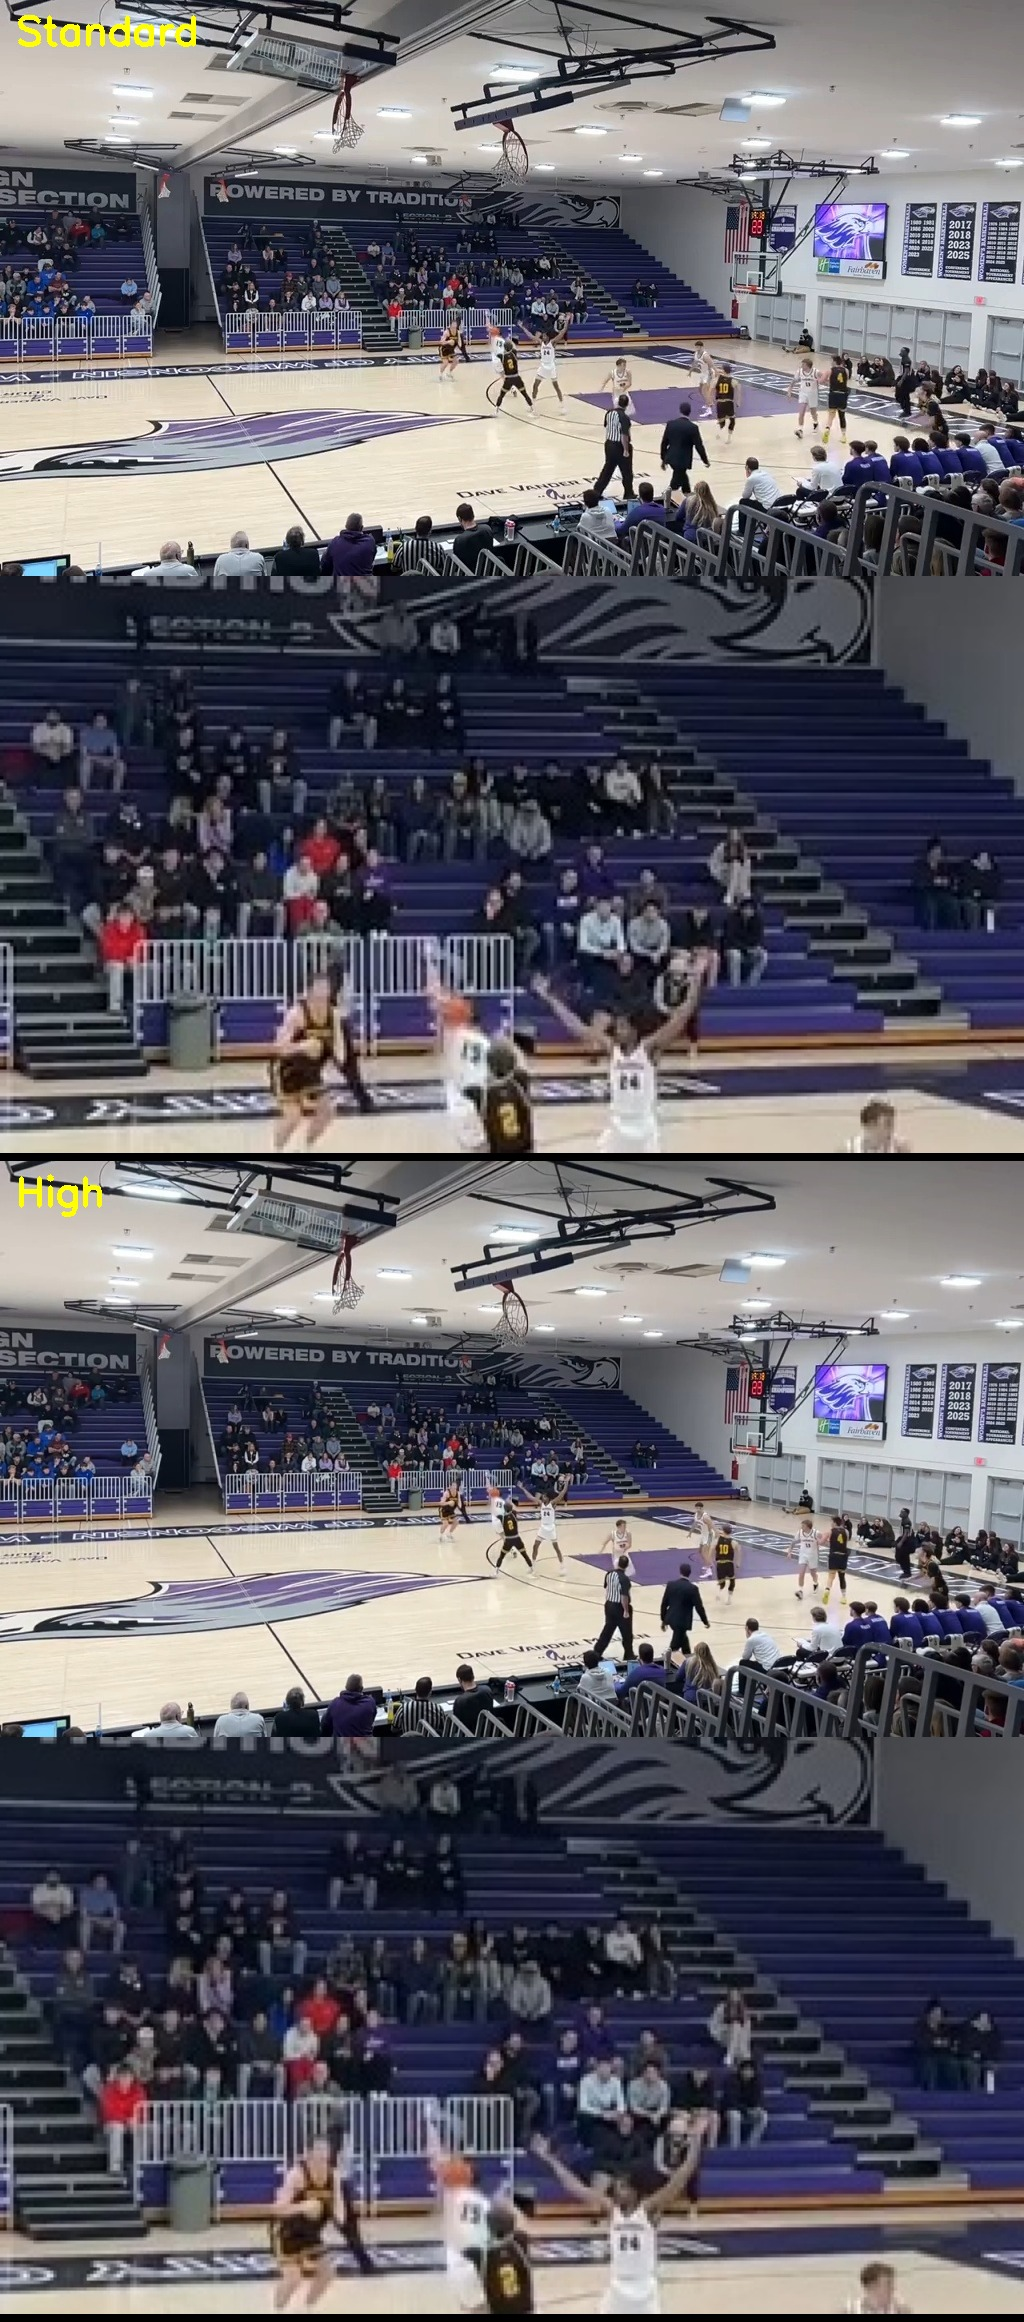

compare_clip05.jpg


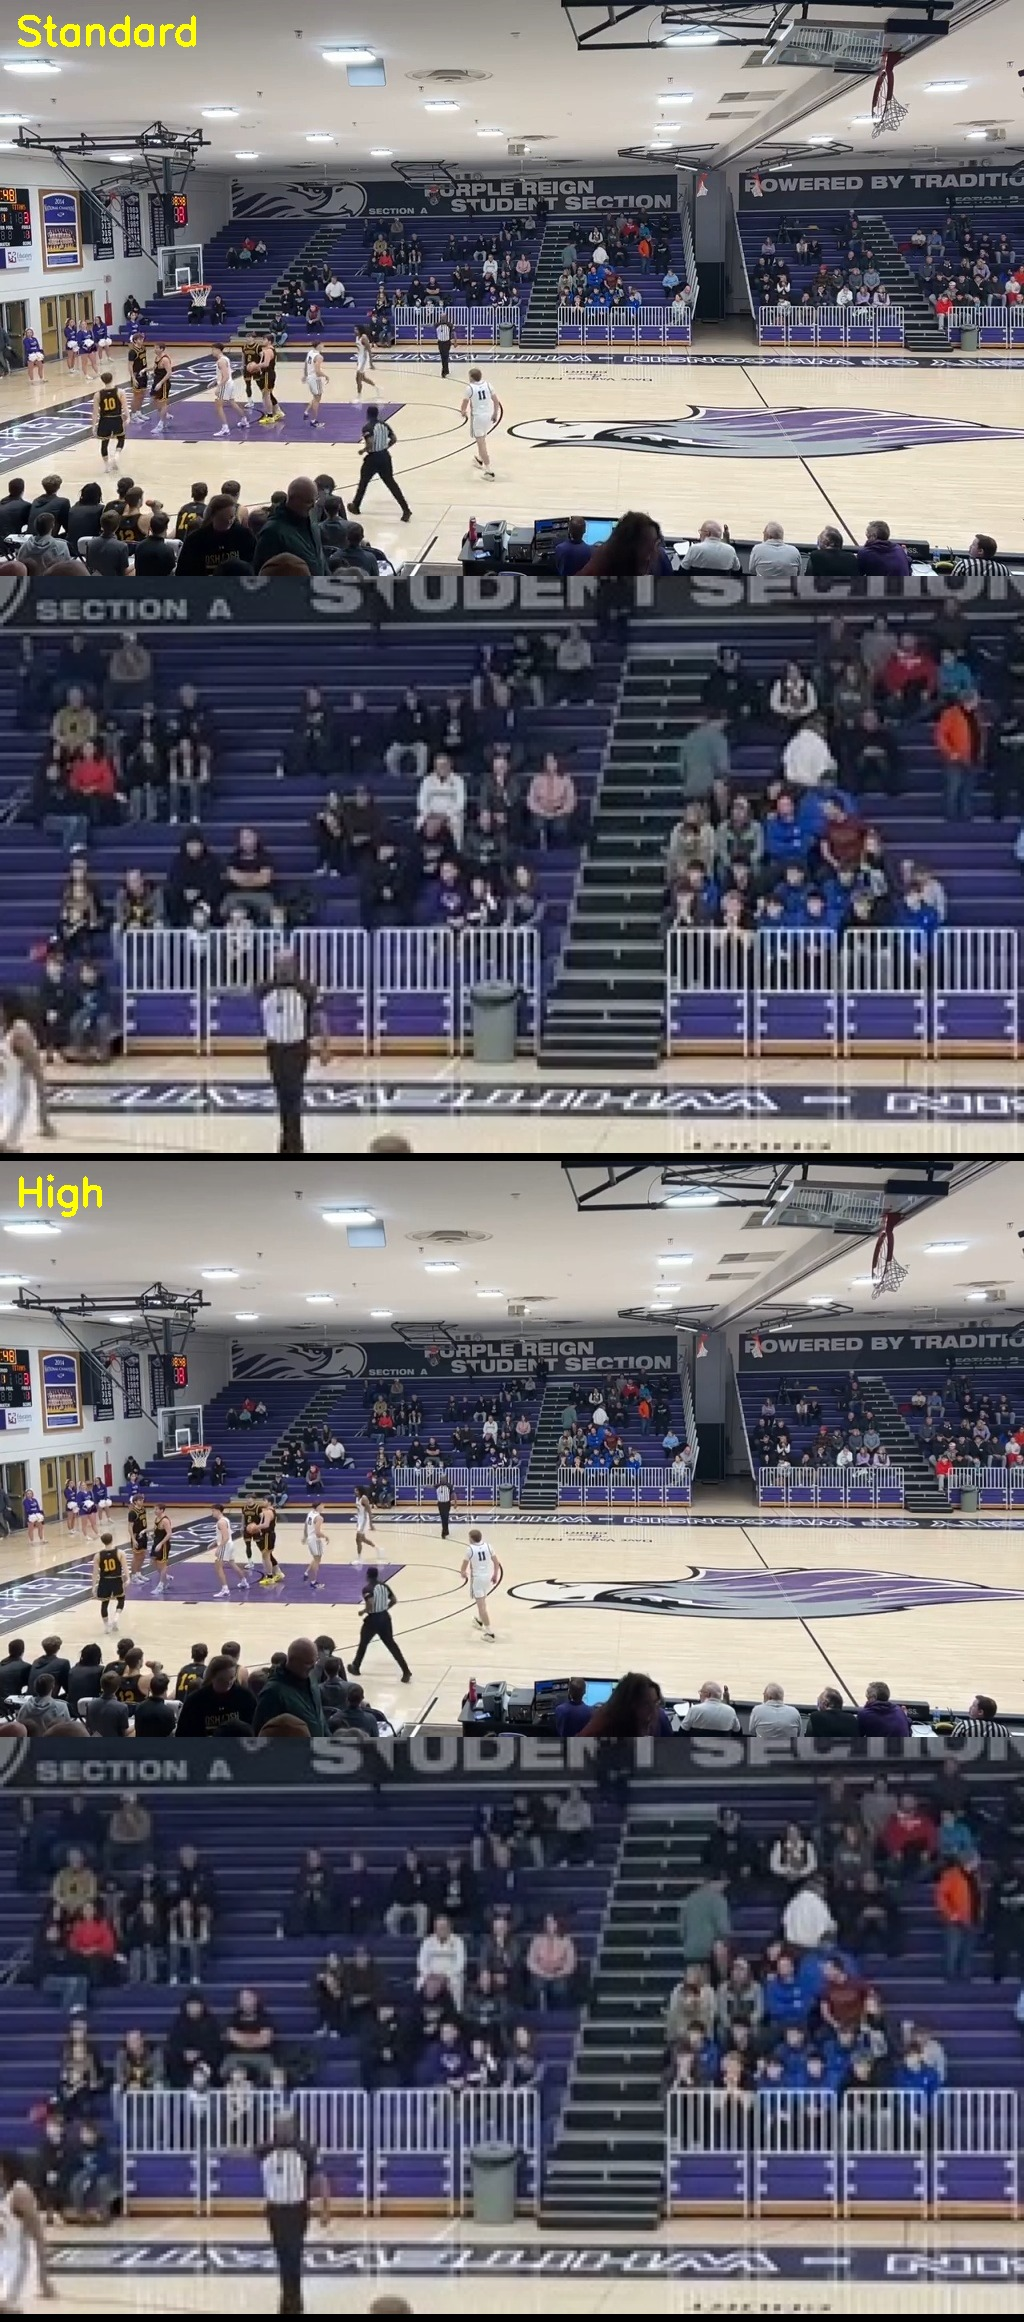

All frames: ./inputs\_quality_test  (<quality>/clipNN_.../full = stream size, w1024 = what the parser saves today)


In [17]:
from IPython.display import Image as _QtImg, display as _qt_display
for _p in qt_compare_files[:QT_CLIPS]:
    print(os.path.basename(_p))
    _qt_display(_QtImg(filename=_p, width=1000))
print(f"All frames: {QT_DIR}  (<quality>/clipNN_.../full = stream size, w1024 = what the parser saves today)")


### Delete the test folder
Set `DELETE_QUALITY_TEST = True` and run when you're done.

In [19]:
DELETE_QUALITY_TEST = False
if DELETE_QUALITY_TEST:
    if os.path.isdir(QT_DIR) and os.path.basename(os.path.normpath(QT_DIR)) == "_quality_test":
        shutil.rmtree(QT_DIR)
        print(f"Deleted {QT_DIR}")
    else:
        print(f"Not deleted -- {QT_DIR} isn't the _quality_test folder")
else:
    print("Nothing deleted (set DELETE_QUALITY_TEST = True)")


Nothing deleted (set DELETE_QUALITY_TEST = True)
